## 1: Imports and Parameters
Install and import the necessary libraries (numpy, pandas, networkx, pyplot) and define the main parameters of the model

In [1]:
# Install the libraries

%pip install numpy
%pip install pandas 
%pip install networkx
%pip install matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the libraries

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


In [3]:
# Define the main parameters

# Number of nodes
N = 10000

# Parameter c (average number of links for each node)
c = 0.95

# Parameter p (probability that a node is linked to another)
p = c/N

# Parameter lambda (proxy for market depth)
lam = 1

## 2: Random Graph Generation
Generate the Random Graph with the parameters above

In [4]:
G = nx.fast_gnp_random_graph(N, p)

In [5]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Average degree:", sum(dict(G.degree()).values())/N) 

Number of nodes: 10000
Number of edges: 4730
Average degree: 0.946


## 3: Connected Components Identification
Identification of the connected components of the graph

In [6]:
# Visualize the graph's connected components

components = list(nx.connected_components(G))
n_components = len(components)  

print("Number of connected components:", n_components)

cluster_sizes = []

for component in components:
    cluster_sizes.append(len(component))

print("Average size of connected components:", np.mean(cluster_sizes))
print("Largest connected component size:", max(cluster_sizes))

#Check (must sum to N)
#print("Sum of sizes of connected components:", sum(cluster_sizes))


Number of connected components: 5271
Average size of connected components: 1.8971732119142477
Largest connected component size: 253


## 4: One Period Market Simulation
Here we simulate the creation of opinions between clusters, and therefore the market aggregate demand 

In [7]:
# First we need to set the parameter a, s.t. 2a is the prob. that the cluster is active
# Thus, 0 < a < 0.5

a = 0.2

In [8]:
# Draw decision for each connected component, i.e. if the component is buying,
# selling or inactive

cluster_decisions = np.random.choice([-1, 0, 1], size=n_components, p=[a, 1-2*a, a])

cluster_contributes = cluster_decisions*np.array(cluster_sizes)

#type check
#print(type(cluster_decisions), type (np.array(cluster_sizes)), type(cluster_contributes))

print("Cluster contributes:", cluster_contributes)

D = sum(cluster_contributes)

print("Aggregate demand D:", D)

Cluster contributes: [-2 87  1 ...  1  0  1]
Aggregate demand D: 66


## 5: Repeated independent one-period simulations
Here we repeat the previous model multiple times

In [9]:
# We now define a functions that computes the one period market simulation 
# and returns the aggregate demand D, given the parameters N, c and a

def one_period_simulation(N, c, a, lam):
    p = c/N
    G = nx.fast_gnp_random_graph(N, p)
    components = list(nx.connected_components(G))
    n_components = len(components)  
    cluster_sizes = [len(component) for component in components]
    cluster_decisions = np.random.choice([-1, 0, 1], size=n_components, p=[a, 1-2*a, a])
    cluster_contributes = cluster_decisions*np.array(cluster_sizes)
    D = sum(cluster_contributes)
    delta_x = D/lam

    results = pd.DataFrame({
        'Delta_X': [delta_x],
        'Aggregate Demand': [D],
        'Number of Clusters': [n_components],
        'Active Clusters': [np.sum(abs(cluster_decisions))],
        'Largest Cluster': [max(cluster_sizes)],
    })

    return results

print(one_period_simulation(N, c, a, lam))


   Delta_X  Aggregate Demand  Number of Clusters  Active Clusters  \
0    519.0               519                5249             2086   

   Largest Cluster  
0              182  


In [10]:
# Now we define a function that computes the market simulation for T periods and returns 
# a DataFrame with the results for each period

T = 10_000

N = 1000
c = 0.95
a = 0.2
lam = 1

def market_simulation(T, N, c, a, lam):
    for t in range(T):
        results = one_period_simulation(N, c, a, lam)
        if t == 0:
            df_results = results
        else:
            df_results = pd.concat([df_results, results], ignore_index=True)
    return df_results        

#print(market_simulation(T, N, c, a, lam))

In [11]:
# Let's visualize mean results of the market simulation for T periods

mean_results = market_simulation(T, N, c, a, lam).mean()

In [12]:
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Delta_X                 0.2206
Aggregate Demand        0.2206
Number of Clusters    526.1887
Active Clusters       210.4442
Largest Cluster        68.6411
dtype: float64


## 6: Independent Agent Benchmark

In [13]:
# Now let's simulate the results for c = 0
# This simulates the case where there are no links between the nodes, 
# i.e. each node is isolated and makes its own decision independently of the others

c = 0

mean_results = market_simulation(T, N, c, a, lam).mean()
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Delta_X                  0.0689
Aggregate Demand         0.0689
Number of Clusters    1000.0000
Active Clusters        400.1757
Largest Cluster          1.0000
dtype: float64


## 7: Effect of c 

In [14]:
# Now let's simulate what happens when c is higher than the critical value 1,
# i.e., when the nodes are connected to more than one other node on average

c = 1.5

mean_results = market_simulation(T, N, c, a, lam).mean()
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Delta_X                 4.6772
Aggregate Demand        4.6772
Number of Clusters    287.7531
Active Clusters       115.0065
Largest Cluster       579.4239
dtype: float64


## 8: Return distribution
In this section we analyze the distribution of returns in the Cont-Bouchaud model, to then compare it with a Gaussian benchmark corresponding to the aggregation of independent finite-variance individual demands.
Following Cont and Bouchaud, x(t) is interpreted as the log-price, so that Delta_x=x(t+1)-x(t) represents the one-period log return

In [15]:
T = 10_000

N = 1000
c = 0.95
a = 0.2
lam = 1

results = market_simulation(T, N, c, a, lam)

returns = results['Delta_X'].values

print(results.describe())

            Delta_X  Aggregate Demand  Number of Clusters  Active Clusters  \
count  10000.000000      10000.000000        10000.000000      10000.00000   
mean       0.795100          0.795100          526.162200        210.50720   
std       67.824957         67.824957           21.770142         14.35568   
min     -319.000000       -319.000000          442.000000        162.00000   
25%      -40.000000        -40.000000          512.000000        201.00000   
50%        0.000000          0.000000          527.000000        210.00000   
75%       42.000000         42.000000          541.000000        220.00000   
max      332.000000        332.000000          610.000000        265.00000   

       Largest Cluster  
count     10000.000000  
mean         68.960300  
std          37.612017  
min          15.000000  
25%          42.000000  
50%          59.000000  
75%          86.000000  
max         349.000000  


In [16]:
# Let's compute the excess kurtosis of the returns distribution

print("Excess kurtosis of the returns distribution:", pd.Series(returns).kurt())

# An excess kurtosis greater than 0 indicates that the distribution has heavier tails 
# than a normal distribution, which is a common feature of financial returns.

Excess kurtosis of the returns distribution: 0.879253426949675


Text(0, 0.5, 'Density')

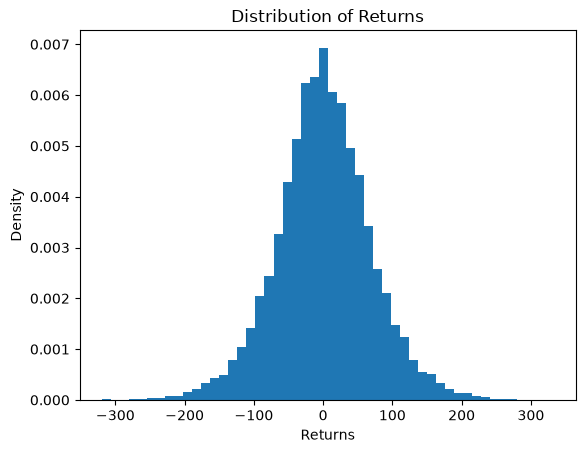

In [17]:
# Now let's visualize the distribution of returns for the market simulation

#plt.figure()

plt.hist(returns, bins=50, density=True)
plt.title("Distribution of Returns")
plt.xlabel("Returns")
plt.ylabel("Density")

#plt.show()

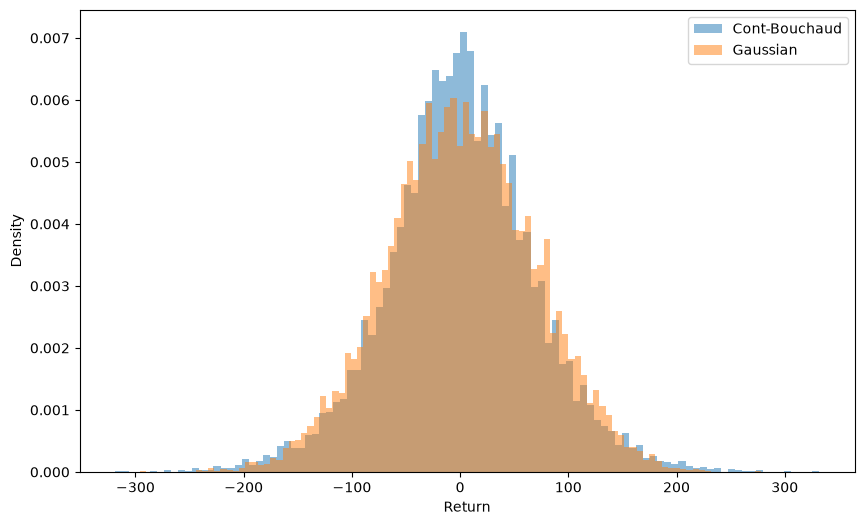

In [18]:
# Let's compare it to a normal distribution with the same mean and standard deviation

# Lets generate a normal distribution with the same mean and standard deviation as the returns
gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
)

# Now let's plot them together

plt.figure(figsize=(10, 6))

plt.hist(
    returns,
    bins=100,
    density=True,
    alpha=0.5,
    label="Cont-Bouchaud"
)

plt.hist(
    gaussian_returns,
    bins=100,
    density=True,
    alpha=0.5,
    label="Gaussian"
)

plt.xlabel("Return")
plt.ylabel("Density")
plt.legend()
plt.show()


In [19]:
# Let's better visualize the tails of the distribution by confronting
# the empirical quantiles of the absolute returns of the two models

standardized_returns = (returns - returns.mean()) / returns.std()
standardized_gaussian_returns = (gaussian_returns - gaussian_returns.mean()) / gaussian_returns.std()

std_returns_abs = np.abs(standardized_returns)
std_gaussian_returns_abs = np.abs(standardized_gaussian_returns)

returns_quantiles = np.quantile(std_returns_abs, [0.9, 0.95, 0.99, 0.999])
gaussian_returns_quantiles = np.quantile(std_gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])   

print("Empirical quantiles of the absolute returns of the Cont-Bouchaud model:", returns_quantiles)
print(f"Empirical quantiles of the absolute returns of the Gaussian model: {gaussian_returns_quantiles}")


Empirical quantiles of the absolute returns of the Cont-Bouchaud model: [1.63966873 2.0377722  2.89304444 3.89564733]
Empirical quantiles of the absolute returns of the Gaussian model: [1.65335323 1.96067529 2.55251594 3.30644136]


In [20]:
# Now let's see how the tails change when we increase the parameter c, 
# and compare them to the Gaussian model with the same mean and standard deviation

c_values = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]

for c in c_values:
    results = market_simulation(T, N, c, a, lam)
    returns = results['Delta_X'].values
    standardized_returns = (returns - returns.mean()) / returns.std()
    std_returns_abs = np.abs(standardized_returns)
    returns_quantiles = np.quantile(std_returns_abs, [0.9, 0.95, 0.99, 0.999])

    gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
    )
    standardized_gaussian_returns = (gaussian_returns - gaussian_returns.mean()) / gaussian_returns.std()
    std_gaussian_returns_abs = np.abs(standardized_gaussian_returns)
    gaussian_returns_quantiles = np.quantile(std_gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])

    print(f"Quantiles of the absolute returns of the Cont-Bouchaud model for c={c}: {returns_quantiles}")
    print(f"Quantiles of the absolute returns of the Gaussian model for c={c}: {gaussian_returns_quantiles}\n")

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.5: [1.67475724 1.98895292 2.54942914 3.17785351]
Quantiles of the absolute returns of the Gaussian model for c=0.5: [1.6477695  1.95858978 2.53675615 3.25070506]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.75: [1.63920301 1.94023795 2.65054495 3.5787862 ]
Quantiles of the absolute returns of the Gaussian model for c=0.75: [1.65107626 1.95448512 2.62217445 3.24616326]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.9: [1.6312279  2.0190187  2.84764225 3.7802517 ]
Quantiles of the absolute returns of the Gaussian model for c=0.9: [1.64303429 1.95279148 2.60260974 3.25243251]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.95: [1.66109879 2.07127232 2.92405531 3.832326  ]
Quantiles of the absolute returns of the Gaussian model for c=0.95: [1.64573117 1.96402713 2.5616019  3.44579588]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0

In [21]:
# Now let's store relevant values for each value of c in a DataFrame and visualize them

c_values = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]

for c in c_values:
    results = market_simulation(T, N, c, a, lam)
    returns = results['Delta_X'].values
    standardized_returns = (returns - returns.mean()) / returns.std()
    std_returns_abs = np.abs(standardized_returns)
    returns_quantiles = np.quantile(std_returns_abs, [0.9, 0.95, 0.99, 0.999])

    returns_mean = returns.mean()
    returns_std = returns.std()
    returns_kurt = pd.Series(returns).kurt()
    

    df_results = pd.DataFrame({
        'c': c,
        'Mean': returns_mean,
        'Std': returns_std,
        'Excess Kurtosis': returns_kurt,
        '90% quantile': returns_quantiles[0],
        '95% quantile': returns_quantiles[1],
        '99% quantile': returns_quantiles[2],
        '99.9% quantile': returns_quantiles[3],
    }, index=[0])

    if c == c_values[0]:
        df_all_results = df_results
    else:
        df_all_results = pd.concat([df_all_results, df_results], ignore_index=True)

In [22]:
# Here we can visualize the results in a table and compare them to the Gaussian model 

print(df_all_results)

gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
)

standardized_gaussian_returns = (gaussian_returns - gaussian_returns.mean()) / gaussian_returns.std()
std_gaussian_returns_abs = np.abs(standardized_gaussian_returns)
gaussian_returns_quantiles = np.quantile(std_gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])

print('\n\n')

print(f"Quantiles of the absolute returns of the Gaussian model: {gaussian_returns_quantiles}\n")

       c    Mean        Std  Excess Kurtosis  90% quantile  95% quantile  \
0  0.500 -0.2799  28.385112        -0.045422      1.630429      1.963004   
1  0.750 -0.5830  39.321883         0.193770      1.642419      1.994233   
2  0.900 -0.4074  56.365248         0.633860      1.639439      2.015295   
3  0.950 -1.3815  67.338941         0.794235      1.657562      2.044411   
4  0.990 -1.0386  77.960674         1.030662      1.680829      2.115957   
5  0.999 -1.3290  81.782804         1.000802      1.691419      2.099109   

   99% quantile  99.9% quantile  
0      2.581632        3.196045  
1      2.634233        3.397167  
2      2.831578        3.718472  
3      2.890133        3.677208  
4      2.911229        3.847714  
5      2.930579        3.725380  



Quantiles of the absolute returns of the Gaussian model: [1.64289756 1.9533859  2.59017534 3.22221954]

